# 01 - Refresh / Content Opportunity Scoring
**Question:** Can trends in clicks, impressions, CTR and position over past months predict which pages will decline next month, so they can be reviewed for refresh first?

Order: run cells top to bottom. Step 2 (schema discovery) tells you the real table/column names. Then fill in the `CFG` dict in cell 3.

In [24]:
!pip install -q duckdb pandas scikit-learn matplotlib huggingface_hub pyarrow

## 1. Config (fill in after you see the schema)

In [25]:
import os, duckdb, pandas as pd, numpy as np
import matplotlib.pyplot as plt

# Colab: add your token in the left sidebar > Secrets (key icon), name it HF_TOKEN, enable "Notebook access"
try:
    from google.colab import userdata
    HF_TOKEN = userdata.get("HF_TOKEN")
except Exception:
    HF_TOKEN = os.environ.get("HF_TOKEN", "PASTE_YOUR_READ_TOKEN_HERE")  # never commit your token

CFG = {
    # hf:// path to the table/parquet files for page-level daily/weekly search data.
    # Example shape: "hf://datasets/<org>/<dataset>/<folder>/*.parquet"
    "source": "hf://datasets/ORG/DATASET/PATH/*.parquet",
    # map warehouse column names -> standard names used below
    "cols": {
        "page": "page_id",        # page identifier (use an ID/hash, never publish URLs)
        "date": "date",
        "clicks": "clicks",
        "impressions": "impressions",
        "position": "position",   # average position
    },
    "min_clicks": 10,       # ignore tiny pages (too noisy)
    "decline_pct": 0.20,    # label = clicks fall by more than 20% next month
}

## 2. Connect and discover schema

In [26]:
!pip install -U -q duckdb

In [27]:
print(len(HF_TOKEN), HF_TOKEN[:3])   # lagbhag 37 aur "hf_" aana chahiye

37 hf_


In [28]:
from getpass import getpass
HF_TOKEN = getpass("HF read token (hf_...): ").strip()
print(len(HF_TOKEN), HF_TOKEN[:3])   # 37 ke aas paas aur "hf_"

HF read token (hf_...): ··········
37 hf_


In [29]:
import os, duckdb
os.environ["HF_TOKEN"] = HF_TOKEN
from huggingface_hub import list_repo_files

REPO = "FlyRank/internship-warehouse"
files = list_repo_files(REPO, repo_type="dataset", token=HF_TOKEN)
print(len(files))
print([f for f in files if "fact_content_daily_performance" in f][:10])
print(sorted({f.split("/")[0] for f in files}))

24
['fact_content_daily_performance/month=2025-01/data_0.parquet', 'fact_content_daily_performance/month=2025-02/data_0.parquet', 'fact_content_daily_performance/month=2025-03/data_0.parquet', 'fact_content_daily_performance/month=2025-04/data_0.parquet', 'fact_content_daily_performance/month=2025-05/data_0.parquet', 'fact_content_daily_performance/month=2025-06/data_0.parquet', 'fact_content_daily_performance/month=2025-07/data_0.parquet', 'fact_content_daily_performance/month=2025-08/data_0.parquet', 'fact_content_daily_performance/month=2025-09/data_0.parquet', 'fact_content_daily_performance/month=2025-10/data_0.parquet']
['.gitattributes', 'README.md', 'dim_clients.parquet', 'dim_content.parquet', 'fact_content_daily_performance', 'fact_content_daily_performance_sample.parquet', 'fact_content_query_90d.parquet']


In [30]:
from getpass import getpass
HF_TOKEN = getpass("naya HF read token: ").strip()


naya HF read token: ··········


In [31]:
from google.colab import userdata
HF_TOKEN = userdata.get("HF_TOKEN").strip()
print("len:", len(HF_TOKEN), "| starts hf_:", HF_TOKEN.startswith("hf_"))

from huggingface_hub import HfApi
try:
    me = HfApi(token=HF_TOKEN).whoami()
    print("OK account:", me["name"])
except Exception as e:
    print("FAIL:", str(e)[:120])

len: 37 | starts hf_: True
OK account: iqragulshaikh


In [32]:
import duckdb
from huggingface_hub import hf_hub_download

con = duckdb.connect()
con.execute("INSTALL httpfs; LOAD httpfs;")
con.execute("CREATE OR REPLACE SECRET hf (TYPE HUGGINGFACE, TOKEN '" + HF_TOKEN + "')")

BASE = "hf://datasets/FlyRank/internship-warehouse"

print("FILES:")
for f in files: print(" ", f)

print("\n--- README ---")
readme = hf_hub_download(REPO, "README.md", repo_type="dataset", token=HF_TOKEN)
print(open(readme).read()[:6000])

for name, path in {
    "fact": f"{BASE}/fact_content_daily_performance/month=*/*.parquet",
    "dim_content": f"{BASE}/dim_content.parquet",
    "dim_clients": f"{BASE}/dim_clients.parquet",
}.items():
    print(f"\n--- DESCRIBE {name} ---")
    print(con.sql(f"DESCRIBE SELECT * FROM read_parquet('{path}')").df()[["column_name","column_type"]].to_string())

FILES:
  .gitattributes
  README.md
  dim_clients.parquet
  dim_content.parquet
  fact_content_daily_performance/month=2025-01/data_0.parquet
  fact_content_daily_performance/month=2025-02/data_0.parquet
  fact_content_daily_performance/month=2025-03/data_0.parquet
  fact_content_daily_performance/month=2025-04/data_0.parquet
  fact_content_daily_performance/month=2025-05/data_0.parquet
  fact_content_daily_performance/month=2025-06/data_0.parquet
  fact_content_daily_performance/month=2025-07/data_0.parquet
  fact_content_daily_performance/month=2025-08/data_0.parquet
  fact_content_daily_performance/month=2025-09/data_0.parquet
  fact_content_daily_performance/month=2025-10/data_0.parquet
  fact_content_daily_performance/month=2025-11/data_0.parquet
  fact_content_daily_performance/month=2025-12/data_0.parquet
  fact_content_daily_performance/month=2026-01/data_0.parquet
  fact_content_daily_performance/month=2026-02/data_0.parquet
  fact_content_daily_performance/month=2026-03/data_

## 3. Aggregate to a page x month panel (done inside DuckDB)

In [35]:
BASE = "hf://datasets/FlyRank/internship-warehouse"
CFG["source"] = f"{BASE}/fact_content_daily_performance/month=*/*.parquet"

tables = {
    "fact": CFG["source"],
    "dim_content": f"{BASE}/dim_content.parquet",
    "dim_clients": f"{BASE}/dim_clients.parquet",
}
for name, path in tables.items():
    print(f"\n--- {name} ---")
    d = con.sql(f"DESCRIBE SELECT * FROM read_parquet('{path}')").df()
    print(d[["column_name", "column_type"]].to_string(index=False))


--- fact ---
             column_name column_type
             report_date        DATE
          client_hash_id     VARCHAR
         content_hash_id     VARCHAR
          client_has_gsc     BOOLEAN
          client_has_ga4     BOOLEAN
      gsc_data_available     BOOLEAN
      ga4_data_available     BOOLEAN
         gsc_impressions      BIGINT
              gsc_clicks      BIGINT
        gsc_sum_position      BIGINT
        gsc_avg_position      DOUBLE
           ga4_pageviews      BIGINT
            ga4_sessions      BIGINT
               ga4_users      BIGINT
    ga4_engaged_sessions      BIGINT
ga4_total_engagement_sec      BIGINT
        sessions_organic      BIGINT
         sessions_direct      BIGINT
       sessions_referral      BIGINT
         sessions_social      BIGINT
           sessions_paid      BIGINT
             sessions_ai      BIGINT
              ai_chatgpt      BIGINT
           ai_perplexity      BIGINT
               ai_gemini      BIGINT
              ai_copilot

In [36]:
import duckdb
con = duckdb.connect()
con.execute("INSTALL httpfs; LOAD httpfs;")
con.execute("CREATE OR REPLACE SECRET hf (TYPE huggingface, TOKEN '" + HF_TOKEN + "')")

In [37]:
from huggingface_hub import snapshot_download
local = snapshot_download(
    "FlyRank/internship-warehouse", repo_type="dataset", token=HF_TOKEN,
    allow_patterns=["dim_*.parquet", "fact_content_daily_performance/*"],
)
BASE = local
CFG["source"] = f"{BASE}/fact_content_daily_performance/month=*/*.parquet"

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 20 files:   0%|          | 0/20 [00:00<?, ?it/s]

## 4. Features (past only) and label (next month)
Features use months t, t-1, t-2. The label looks at t+1 only. Nothing from t+1 leaks into the features.

In [50]:
import duckdb, numpy as np, pandas as pd

# --- token check (Colab Secret mein sirf hf_... token hona chahiye) ---
try:
    HF_TOKEN
except NameError:
    from google.colab import userdata
    HF_TOKEN = userdata.get("HF_TOKEN").strip()
assert HF_TOKEN.startswith("hf_") and len(HF_TOKEN) < 100, "HF_TOKEN galat hai (secret mein sirf token hona chahiye)"

# --- connect ---
con = duckdb.connect()
con.execute("INSTALL httpfs; LOAD httpfs;")
con.execute("CREATE OR REPLACE SECRET hf (TYPE huggingface, TOKEN '" + HF_TOKEN + "')")

BASE = "hf://datasets/FlyRank/internship-warehouse"
SRC = f"{BASE}/fact_content_daily_performance/month=*/*.parquet"
RP = f"read_parquet('{SRC}', hive_partitioning=false)"

# hf:// kaam na kare to local download par chale jao
try:
    desc = con.sql(f"DESCRIBE SELECT * FROM {RP}").df()
except Exception as e:
    print("hf:// fail, local download kar raha hoon:", str(e)[:100])
    from huggingface_hub import snapshot_download
    BASE = snapshot_download("FlyRank/internship-warehouse", repo_type="dataset", token=HF_TOKEN,
                             allow_patterns=["fact_content_daily_performance/*"])
    SRC = f"{BASE}/fact_content_daily_performance/month=*/*.parquet"
    RP = f"read_parquet('{SRC}', hive_partitioning=false)"
    desc = con.sql(f"DESCRIBE SELECT * FROM {RP}").df()

cols = list(desc["column_name"])
print("FACT COLUMNS:")
print(desc[["column_name", "column_type"]].to_string(index=False))

# --- columns khud pehchano ---
lower = {c.lower(): c for c in cols}
def pick(cands, contains=()):
    for c in cands:
        if c in lower: return lower[c]
    for key in contains:
        hit = [orig for low, orig in lower.items() if key in low]
        if hit: return hit[0]
    return None

c_page = pick(["content_id","page_id","content_key","page_key","url_hash","page_hash","page"], ["content","page"])
c_date = pick(["date","day","event_date","performance_date","dt"], ["date"])
c_clk  = pick(["clicks","gsc_clicks","total_clicks"], ["click"])
c_imp  = pick(["impressions","gsc_impressions","total_impressions"], ["impression"])
c_pos  = pick(["avg_position","position","average_position","avg_pos","gsc_position"], ["position"])

picked = {"page": c_page, "date": c_date, "clicks": c_clk, "impressions": c_imp, "position": c_pos}
print("\nPICKED:", picked)
assert all(picked.values()), f"Kuch columns nahi mile {picked}. Upar FACT COLUMNS ki list yahan paste kar dein."

CFG["source"] = SRC
CFG["cols"] = {"page": c_page, "date": c_date, "clicks": c_clk, "impressions": c_imp, "position": c_pos}

# --- page x month panel (DuckDB ke andar) ---
panel = con.sql(f"""
    SELECT "{c_page}" AS page,
           date_trunc('month', CAST("{c_date}" AS DATE)) AS month,
           SUM("{c_clk}")  AS clicks,
           SUM("{c_imp}")  AS impressions,
           SUM("{c_pos}" * "{c_imp}") / NULLIF(SUM("{c_imp}"), 0) AS position
    FROM {RP}
    GROUP BY 1, 2
""").df()
panel = panel.sort_values(["page", "month"]).reset_index(drop=True)
panel["ctr"] = panel["clicks"] / panel["impressions"].replace(0, np.nan)

print("\npanel:", panel.shape, "| months:", panel["month"].min(), "->", panel["month"].max(),
      "| pages:", panel["page"].nunique())

FACT COLUMNS:
             column_name column_type
             report_date        DATE
          client_hash_id     VARCHAR
         content_hash_id     VARCHAR
          client_has_gsc     BOOLEAN
          client_has_ga4     BOOLEAN
      gsc_data_available     BOOLEAN
      ga4_data_available     BOOLEAN
         gsc_impressions      BIGINT
              gsc_clicks      BIGINT
        gsc_sum_position      BIGINT
        gsc_avg_position      DOUBLE
           ga4_pageviews      BIGINT
            ga4_sessions      BIGINT
               ga4_users      BIGINT
    ga4_engaged_sessions      BIGINT
ga4_total_engagement_sec      BIGINT
        sessions_organic      BIGINT
         sessions_direct      BIGINT
       sessions_referral      BIGINT
         sessions_social      BIGINT
           sessions_paid      BIGINT
             sessions_ai      BIGINT
              ai_chatgpt      BIGINT
           ai_perplexity      BIGINT
               ai_gemini      BIGINT
              ai_copilot

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))


panel: (2871202, 6) | months: 2025-01-01 00:00:00 -> 2026-06-01 00:00:00 | pages: 427292


## 5. Time-aware split
Train on older months, test on the newest ones. One month is skipped between them, because a train row's label peeks one month ahead and would otherwise overlap with the test period.

In [51]:
for name in ["con", "panel", "data", "FEATS"]:
    print(f"{name:6}", "OK" if name in globals() else "MISSING")

con    OK
panel  OK
data   OK
FEATS  OK


## 6. Baseline vs model (same split)

FACT COLUMNS:
             column_name column_type
             report_date        DATE
          client_hash_id     VARCHAR
         content_hash_id     VARCHAR
          client_has_gsc     BOOLEAN
          client_has_ga4     BOOLEAN
      gsc_data_available     BOOLEAN
      ga4_data_available     BOOLEAN
         gsc_impressions      BIGINT
              gsc_clicks      BIGINT
        gsc_sum_position      BIGINT
        gsc_avg_position      DOUBLE
           ga4_pageviews      BIGINT
            ga4_sessions      BIGINT
               ga4_users      BIGINT
    ga4_engaged_sessions      BIGINT
ga4_total_engagement_sec      BIGINT
        sessions_organic      BIGINT
         sessions_direct      BIGINT
       sessions_referral      BIGINT
         sessions_social      BIGINT
           sessions_paid      BIGINT
             sessions_ai      BIGINT
              ai_chatgpt      BIGINT
           ai_perplexity      BIGINT
               ai_gemini      BIGINT
              ai_copilot

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))


panel: (2871202, 7) | months: 2025-01-01 -> 2026-06-01 | pages: 427292

data: (89088, 12) | pages: 25964 | positive rate: 0.449
features: ['clicks', 'chg_clicks_1', 'chg_clicks_2', 'chg_impr_1', 'ctr', 'chg_ctr_1', 'position', 'chg_pos_1', 'volatility']
labelable months: ['2025-03-01', '2025-04-01', '2025-05-01', '2025-06-01', '2025-07-01', '2025-08-01', '2025-09-01', '2025-10-01', '2025-11-01', '2025-12-01', '2026-01-01', '2026-02-01', '2026-03-01', '2026-04-01', '2026-05-01']
train rows: 45860 | test rows: 30483 | base rate train/test: 0.348 0.565


,ROC AUC,PR AUC,Precision@100
Baseline (persistence),0.477,0.582,0.630
Logistic Regression,0.564,0.613,0.570
Gradient Boosting,0.585,0.640,0.780
Random (base rate),0.500,0.565,0.565


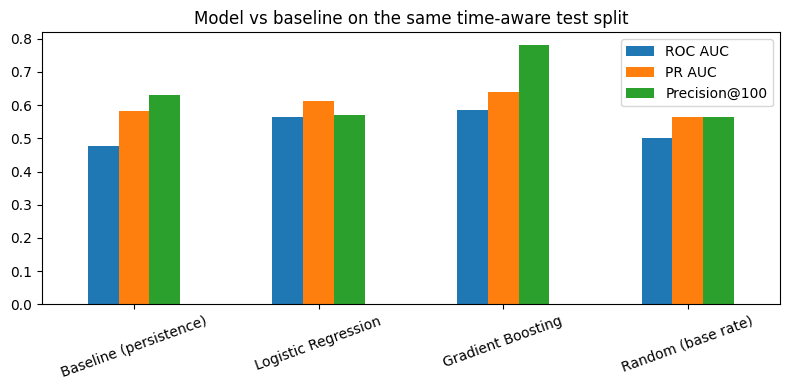

,rank,risk_score,reason_code,action,chg_clicks_1,chg_pos_1
47225,1,0.909,RANK_SLIPPING,content refresh + internal links,-0.474,246.019
72652,2,0.906,STABLE_MONITOR,monitor,-0.794,-28546.818
37078,3,0.901,DECLINING_FAST,refresh/rewrite review,-0.462,-141.916
30823,4,0.900,STABLE_MONITOR,monitor,0.100,-404.392
51250,5,0.900,STABLE_MONITOR,monitor,-0.929,-57394.503
7338,6,0.899,DECLINING_FAST,refresh/rewrite review,-0.519,-342.977
4058,7,0.897,RANK_SLIPPING,content refresh + internal links,-0.222,23.016
7962,8,0.895,RANK_SLIPPING,content refresh + internal links,-0.200,268.893
10907,9,0.887,STABLE_MONITOR,monitor,-0.050,-248.334
42645,10,0.885,STABLE_MONITOR,monitor,-0.807,-2451.066


reason_code
RANK_SLIPPING        9790
STABLE_MONITOR       3745
RECOVERING           2118
DECLINING_FAST        688
HIGH_IMPR_LOW_CTR       5
Name: count, dtype: int64


In [52]:
import os, duckdb, numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import roc_auc_score, average_precision_score

# ---------- 1) token ----------
try:
    HF_TOKEN
except NameError:
    from google.colab import userdata
    HF_TOKEN = userdata.get("HF_TOKEN").strip()
assert HF_TOKEN.startswith("hf_") and len(HF_TOKEN) < 100, "HF_TOKEN galat hai (secret mein sirf hf_... token hona chahiye)"

# ---------- 2) connect ----------
con = duckdb.connect()
con.execute("INSTALL httpfs; LOAD httpfs;")
con.execute("CREATE OR REPLACE SECRET hf (TYPE huggingface, TOKEN '" + HF_TOKEN + "')")
BASE = "hf://datasets/FlyRank/internship-warehouse"
SRC = f"{BASE}/fact_content_daily_performance/month=*/*.parquet"
RP = f"read_parquet('{SRC}', hive_partitioning=false)"
try:
    desc = con.sql(f"DESCRIBE SELECT * FROM {RP}").df()
except Exception as e:
    print("hf:// fail, local download:", str(e)[:100])
    from huggingface_hub import snapshot_download
    BASE = snapshot_download("FlyRank/internship-warehouse", repo_type="dataset", token=HF_TOKEN,
                             allow_patterns=["fact_content_daily_performance/*"])
    SRC = f"{BASE}/fact_content_daily_performance/month=*/*.parquet"
    RP = f"read_parquet('{SRC}', hive_partitioning=false)"
    desc = con.sql(f"DESCRIBE SELECT * FROM {RP}").df()

print("FACT COLUMNS:")
print(desc[["column_name", "column_type"]].to_string(index=False))

# ---------- 3) columns pehchano ----------
lower = {c.lower(): c for c in desc["column_name"]}
def pick(cands, contains=()):
    for c in cands:
        if c in lower: return lower[c]
    for key in contains:
        hit = [o for l, o in lower.items() if key in l]
        if hit: return hit[0]
    return None
picked = {
    "page": pick(["content_id","page_id","content_key","page_key","url_hash","page_hash","page"], ["content","page"]),
    "date": pick(["date","day","event_date","performance_date","dt"], ["date"]),
    "clicks": pick(["clicks","gsc_clicks","total_clicks"], ["click"]),
    "impressions": pick(["impressions","gsc_impressions","total_impressions"], ["impression"]),
    "position": pick(["avg_position","position","average_position","avg_pos","gsc_position"], ["position"]),
}
print("\nPICKED:", picked)
assert all(picked.values()), "Kuch columns nahi mile: upar FACT COLUMNS ki list yahan paste karein"
c = picked

# ---------- 4) page x month panel ----------
panel = con.sql(f"""
    SELECT "{c['page']}" AS page,
           date_trunc('month', CAST("{c['date']}" AS DATE)) AS month,
           SUM("{c['clicks']}") AS clicks,
           SUM("{c['impressions']}") AS impressions,
           SUM("{c['position']}" * "{c['impressions']}") / NULLIF(SUM("{c['impressions']}"), 0) AS position
    FROM {RP}
    GROUP BY 1, 2
""").df()
panel["month"] = pd.to_datetime(panel["month"])
for col in ["clicks", "impressions", "position"]:
    panel[col] = pd.to_numeric(panel[col], errors="coerce")
panel["ctr"] = panel["clicks"] / panel["impressions"].replace(0, np.nan)
panel = panel.dropna(subset=["page", "month"]).sort_values(["page", "month"]).reset_index(drop=True)
panel["mi"] = panel["month"].dt.year * 12 + panel["month"].dt.month
print("\npanel:", panel.shape, "| months:", panel["month"].min().date(), "->", panel["month"].max().date(),
      "| pages:", panel["page"].nunique())

# ---------- 5) features + label ----------
CFG = {"min_clicks": 10, "decline_pct": 0.20}
g = panel.groupby("page", sort=False)
for col in ["clicks", "impressions", "ctr", "position"]:
    panel[f"{col}_l1"] = g[col].shift(1)
    panel[f"{col}_l2"] = g[col].shift(2)
panel["clicks_next"] = g["clicks"].shift(-1)
panel["mi_l2"] = g["mi"].shift(2)
panel["mi_next"] = g["mi"].shift(-1)
panel["gap_ok"] = ((panel["mi"] - panel["mi_l2"]) == 2) & ((panel["mi_next"] - panel["mi"]) == 1)

f = pd.DataFrame({"page": panel["page"], "month": panel["month"]})
f["clicks"]       = panel["clicks"]
f["chg_clicks_1"] = (panel["clicks"] - panel["clicks_l1"]) / (panel["clicks_l1"] + 1)
f["chg_clicks_2"] = (panel["clicks_l1"] - panel["clicks_l2"]) / (panel["clicks_l2"] + 1)
f["chg_impr_1"]   = (panel["impressions"] - panel["impressions_l1"]) / (panel["impressions_l1"] + 1)
f["ctr"]          = panel["ctr"]
f["chg_ctr_1"]    = panel["ctr"] - panel["ctr_l1"]
f["position"]     = panel["position"]
f["chg_pos_1"]    = panel["position"] - panel["position_l1"]
_c = panel[["clicks", "clicks_l1", "clicks_l2"]]
f["volatility"]   = _c.std(axis=1) / (_c.mean(axis=1) + 1)
f["y"]            = (panel["clicks_next"] < (1 - CFG["decline_pct"]) * panel["clicks"]).astype(int)

mask = (panel["gap_ok"] & (panel["clicks"] >= CFG["min_clicks"])
        & panel["clicks_next"].notna() & panel["clicks_l2"].notna())
data = f[mask].replace([np.inf, -np.inf], np.nan).dropna().reset_index(drop=True)
FEATS = [x for x in data.columns if x not in ("page", "month", "y")]
print("\ndata:", data.shape, "| pages:", data["page"].nunique(), "| positive rate:", round(data["y"].mean(), 3))
print("features:", FEATS)

# ---------- 6) time-aware split ----------
months = sorted(data["month"].unique())
print("labelable months:", [str(pd.Timestamp(m).date()) for m in months])
assert len(months) >= 4, f"Sirf {len(months)} labelable mahine hain, kam az kam 4 chahiye"
n_test = 2
test_months, train_months = months[-n_test:], months[:-(n_test + 1)]
train = data[data["month"].isin(train_months)].copy()
test  = data[data["month"].isin(test_months)].copy()
assert train["month"].max() < test["month"].min()
assert train["y"].nunique() == 2 and test["y"].nunique() == 2, "Label mein dono classes nahi hain"
print("train rows:", len(train), "| test rows:", len(test),
      "| base rate train/test:", round(train["y"].mean(), 3), round(test["y"].mean(), 3))

# ---------- 7) baseline vs model ----------
Xtr, ytr, Xte, yte = train[FEATS], train["y"], test[FEATS], test["y"]
lr = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, class_weight="balanced")).fit(Xtr, ytr)
gb = HistGradientBoostingClassifier(max_depth=4, learning_rate=0.05, max_iter=300, random_state=42).fit(Xtr, ytr)

def p_at_k(y, s, k=100):
    idx = np.argsort(-np.asarray(s))[:k]
    return np.asarray(y)[idx].mean()

scores = {"Baseline (persistence)": -test["chg_clicks_1"].values,
          "Logistic Regression": lr.predict_proba(Xte)[:, 1],
          "Gradient Boosting": gb.predict_proba(Xte)[:, 1]}
res = pd.DataFrame({n: {"ROC AUC": roc_auc_score(yte, s),
                        "PR AUC": average_precision_score(yte, s),
                        "Precision@100": p_at_k(yte, s, 100)} for n, s in scores.items()}).T
res.loc["Random (base rate)"] = [0.5, yte.mean(), yte.mean()]
display(res.round(3))
ax = res.plot.bar(figsize=(8, 4), rot=20)
ax.set_title("Model vs baseline on the same time-aware test split")
plt.tight_layout(); plt.savefig("results_model_vs_baseline.png", dpi=150); plt.show()

# ---------- 8) ranked actions ----------
def reason(r):
    if r["chg_clicks_1"] < -0.3 and r["chg_clicks_2"] < -0.1: return "DECLINING_FAST"
    if r["chg_pos_1"] > 1.5:                                  return "RANK_SLIPPING"
    if r["chg_impr_1"] > 0.1 and r["chg_ctr_1"] < -0.005:     return "HIGH_IMPR_LOW_CTR"
    if r["chg_clicks_1"] > 0.2:                               return "RECOVERING"
    return "STABLE_MONITOR"
ACTION = {"DECLINING_FAST": "refresh/rewrite review", "RANK_SLIPPING": "content refresh + internal links",
          "HIGH_IMPR_LOW_CTR": "title/meta review", "RECOVERING": "protect", "STABLE_MONITOR": "monitor"}

latest = test[test["month"] == test["month"].max()].copy()
latest["risk_score"]  = gb.predict_proba(latest[FEATS])[:, 1]
latest["reason_code"] = latest.apply(reason, axis=1)
latest["action"]      = latest["reason_code"].map(ACTION)
ranked = latest.sort_values("risk_score", ascending=False).head(25).copy()
ranked.insert(0, "rank", range(1, len(ranked) + 1))      # anonymous rank, page ID nahi
display(ranked[["rank", "risk_score", "reason_code", "action", "chg_clicks_1", "chg_pos_1"]].round(3))

# ---------- 9) save ----------
os.makedirs("outputs", exist_ok=True)
res.round(4).to_csv("outputs/results_table.csv")
ranked[["rank", "risk_score", "reason_code", "action"]].round(4).to_csv("outputs/top_recommendations_anonymized.csv", index=False)
print(latest["reason_code"].value_counts())

## 7. Action engine: ranked pages with reason codes

In [53]:
os.makedirs("outputs", exist_ok=True)
res.round(4).to_csv("outputs/results_table.csv")
ranked[["rank", "risk_score", "reason_code", "action"]].round(4).to_csv(
    "outputs/top_recommendations_anonymized.csv", index=False)
print(latest["reason_code"].value_counts())
print("saved:", os.listdir("outputs"))

reason_code
RANK_SLIPPING        9790
STABLE_MONITOR       3745
RECOVERING           2118
DECLINING_FAST        688
HIGH_IMPR_LOW_CTR       5
Name: count, dtype: int64
saved: ['top_recommendations_anonymized.csv', 'results_table.csv']


## Next
- Check calibration and feature importance (`permutation_importance`) for the Results section.
- Add limitations: observational, one site/portfolio, no causal claims, seasonality.
- Before publishing: no URLs, domains, client names or raw exports in anything public.